Initializing Robust Training...
Epoch  | Profit     | Regret     | IR        
0      | -6.7911    | 2.7122     | 0.0000    
50     | -0.3624    | 0.5135     | 0.0000    
100    | 5.3055     | -0.2753    | 0.0159    
150    | 6.2171     | 0.0679     | 0.0000    
200    | 6.6998     | -0.0055    | 0.0002    
250    | 6.1174     | -0.1080    | 0.0000    
300    | 6.5332     | 0.0882     | 0.0000    
350    | 6.7310     | -0.1004    | 0.0000    
400    | 7.0360     | -0.0866    | 0.0000    
450    | 6.7435     | -0.0825    | 0.0000    
500    | 7.2597     | -0.1915    | 0.0002    
550    | 6.5170     | -0.1634    | 0.0000    
600    | 6.1729     | -0.3049    | 0.0000    
650    | 6.1214     | -0.0343    | 0.0067    
700    | 7.2141     | 0.0074     | 0.0000    
750    | 6.2207     | 0.0975     | 0.0000    
800    | 6.9717     | 0.0120     | 0.0000    
850    | 7.4545     | 0.0000     | 0.0034    
900    | 7.4886     | 0.0103     | 0.0069    
950    | 7.5356     | 0.0054     | 0.0000    
10

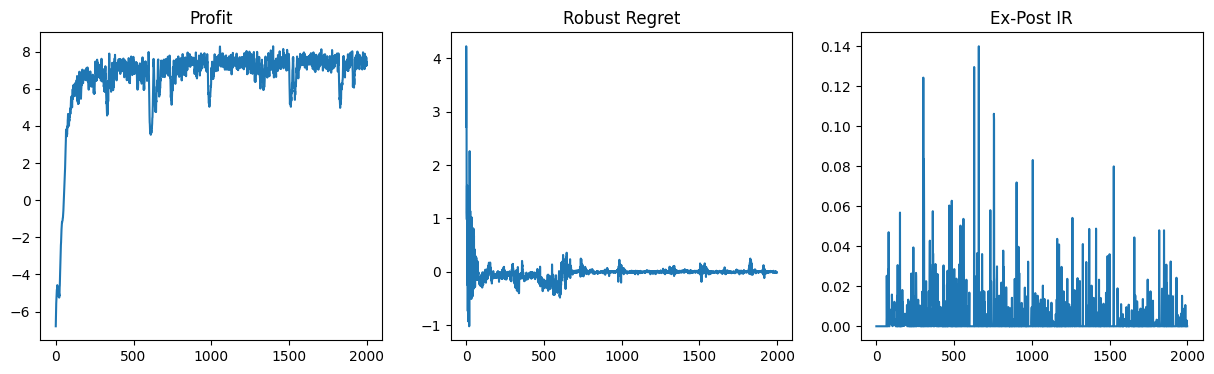

Training Complete & Saved.


In [ ]:
# discrete single
import os, json, time, pickle, shutil
from typing import Any, Dict, List
import jax
import jax.numpy as jnp
import haiku as hk
import optax
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Robust Regret Logic
# ============================================================
def compute_robust_regret_scan(
    mechanism_net,
    auction,
    params_mech,
    params_policy,
    policy_network,
    key,
    temperature,
    num_random_probes=2048
):
    k_truth, k_pol, k_rand = jax.random.split(key, 3)

    # --- A. Truthful Utility ---
    def run_truthful(carry, t):
        state, rng, cum_u = carry
        rng, rng_step = jax.random.split(rng)
        report = state.current_type

        alloc, pay = mechanism_net.apply(params_mech, state, report, auction)
        # Slice to ensure shapes match (remove dummy if present)
        alloc = alloc[:auction.num_buyers]
        pay = pay[:auction.num_buyers]

        util = jnp.sum(state.current_type * alloc - pay)
        cum_u += (auction.discount ** t) * util
        next_state = auction.get_next_state(state, report, alloc, rng_step)
        return (next_state, rng, cum_u), None

    state_init = auction.get_initial_state(k_truth)
    (_, _, u_truthful), _ = jax.lax.scan(run_truthful, (state_init, k_truth, 0.0), jnp.arange(auction.num_horizons))

    # --- B. Gradient Policy Utility ---
    u_policy = -1e9
    if params_policy is not None:
        belief_init = auction.get_initial_belief_state(state_init)
        policy = DiffPolicy(policy_network, params_policy, temperature)

        def run_policy(carry, t):
            state, b_state, rng, cum_u = carry
            rng, rng_rep, rng_step = jax.random.split(rng, 3)

            report = policy(b_state, auction, rng_rep)
            alloc, pay = mechanism_net.apply(params_mech, state, report, auction)
            alloc = alloc[:auction.num_buyers]
            pay = pay[:auction.num_buyers]

            util = jnp.sum(state.current_type * alloc - pay)
            cum_u += (auction.discount ** t) * util
            ns, nbs = AuctionSimulator.step(auction, state, b_state, report, alloc, rng_step)
            return (ns, nbs, rng, cum_u), None

        (_, _, _, u_policy), _ = jax.lax.scan(run_policy, (state_init, belief_init, k_pol, 0.0), jnp.arange(auction.num_horizons))

    # --- C. Brute Force Probes ---
    const_indices = jnp.tile(jnp.arange(auction.num_types)[:, None], (1, auction.num_horizons))
    rand_indices = jax.random.randint(k_rand, (num_random_probes, auction.num_horizons), 0, auction.num_types)
    all_probes = jnp.concatenate([const_indices, rand_indices], axis=0)

    def eval_probe(probe_idx_seq):
        def run_probe(carry, t):
            state, rng, cum_u = carry
            rng, rng_step = jax.random.split(rng)

            # Buyer 0 lies; others truthful
            val_lie = auction.buyer_types[0, probe_idx_seq[t]]
            report = state.current_type.at[0].set(val_lie)

            alloc, pay = mechanism_net.apply(params_mech, state, report, auction)
            alloc = alloc[:auction.num_buyers]
            pay = pay[:auction.num_buyers]

            util = (state.current_type[0] * alloc[0] - pay[0]).squeeze()
            cum_u += (auction.discount ** t) * util

            next_state = auction.get_next_state(state, report, alloc, rng_step)
            return (next_state, rng, cum_u), None

        (_, _, u_probe), _ = jax.lax.scan(run_probe, (state_init, k_rand, 0.0), jnp.arange(auction.num_horizons))
        return u_probe

    u_probes = jax.vmap(eval_probe)(all_probes)
    u_best_probe = jnp.max(u_probes)

    max_deviant_util = jnp.maximum(u_policy, u_best_probe)
    regret = max_deviant_util - u_truthful

    return regret, u_truthful, u_policy, u_best_probe

# ============================================================
# 2. Training Loop (Fixed s_init Error)
# ============================================================
def train_robust_mechanism(
    auction, mechanism_net, policy_net,
    num_outer_epochs=2000,
    lr_theta=1e-4, lr_w=5e-4,
    beta_ic=20.0, beta_ir=20.0,
    num_samples=64, num_probes=1024
):
    prng = hk.PRNGSequence(2026)

    # Init
    s_init = auction.get_initial_state(next(prng))
    params_m = mechanism_net.init(next(prng), s_init, jnp.zeros((auction.num_buyers, auction.num_goods)), auction)
    opt_m = optax.adam(lr_theta)
    state_m = opt_m.init(params_m)

    b_init = auction.get_initial_belief_state(s_init)
    params_p = policy_net.init(next(prng), b_init, auction)
    opt_p = optax.adam(lr_w)
    state_p = opt_p.init(params_p)

    # --- Loss Functions ---
    def loss_outer_imp(theta, p_params, key, temp):
        k1, k2, k3 = jax.random.split(key, 3)

        # 1. Robust Regret
        def get_regret(k):
            r, _, _, _ = compute_robust_regret_scan(
                mechanism_net, auction, theta, p_params, policy_net, k, temp, num_probes
            )
            return r
        reg_batch = jax.vmap(get_regret)(jax.random.split(k1, num_samples))
        reg = jnp.mean(reg_batch)

        # 2. Profit
        def get_profit(k):
            mech = Mechanism(mechanism_net, theta)
            return AuctionSimulator.estimate_cumulative_profit(auction, mech, 1, k)
        prof_batch = jax.vmap(get_profit)(jax.random.split(k2, num_samples))
        prof = jnp.mean(prof_batch)

        # 3. Ex-Post IR (Fixed Logic)
        def get_ir(k):
            mech = Mechanism(mechanism_net, theta)
            # Sample a BATCH of size 1
            s_batch = AuctionSimulator.sample_init_state(auction, 1, k)

            # [FIX] Strip the batch dimension to get a single State object
            # s_batch is (1, ...), we want (...)
            s_single = jax.tree_util.tree_map(lambda x: x[0], s_batch)

            # Now pass the single state to calculate rewards
            u = AuctionSimulator.sample_cumulative_rewards(auction, s_single, mech, k)
            return jnp.sum(jax.nn.relu(-u))

        ir_batch = jax.vmap(get_ir)(jax.random.split(k3, num_samples))
        ir = jnp.mean(ir_batch)

        reg_plus = jnp.maximum(0.0, reg)
        loss = -prof + beta_ic * reg_plus + beta_ir * ir
        return loss, (prof, reg, ir)

    @jax.jit
    def loss_outer(theta, p_params, key, temp):
        return loss_outer_imp(theta, p_params, key, temp)

    @jax.jit
    def update_policy(p_params, theta, opt_state, key, temp):
        def regret_obj(p):
            mech = Mechanism(mechanism_net, theta)
            pol = DiffPolicy(policy_net, p, temp)
            return AuctionSimulator.estimate_cumulative_regret(auction, mech, pol, num_samples, key)

        (reg, grads) = jax.value_and_grad(regret_obj)(p_params)
        # Use tree_util here as well for safety
        grad_ascent = jax.tree_util.tree_map(lambda x: -x, grads)
        updates, opt_state = opt_p.update(grad_ascent, opt_state, p_params)
        return reg, optax.apply_updates(p_params, updates), opt_state

    # --- Loop ---
    logs = {"loss": [], "profit": [], "regret": [], "ir": []}

    print(f"{'Epoch':<6} | {'Profit':<10} | {'Regret':<10} | {'IR':<10}")

    for epoch in range(num_outer_epochs):
        temp = max(0.05, 1.0 * np.exp(-0.005 * epoch))

        # 1. Train Policy (Inner Loop)
        for _ in range(100):
            key_inner = next(prng)
            _, params_p, state_p = update_policy(params_p, params_m, state_p, key_inner, temp)

        # 2. Train Mechanism (Outer Step)
        key_outer = next(prng)
        (l, (prof, reg, ir)), grads = jax.value_and_grad(loss_outer, has_aux=True)(params_m, params_p, key_outer, temp)

        updates, state_m = opt_m.update(grads, state_m, params_m)
        params_m = optax.apply_updates(params_m, updates)

        logs["loss"].append(float(l))
        logs["profit"].append(float(prof))
        logs["regret"].append(float(reg))
        logs["ir"].append(float(ir))

        if epoch % 50 == 0:
            print(f"{epoch:<6d} | {float(prof):<10.4f} | {float(reg):<10.4f} | {float(ir):<10.4f}")

    return params_m, params_p, logs

# ============================================================
# 3. Execution
# ============================================================
print("Initializing Robust Training...")

mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = build_discrete_policy_net_minimal(stop_grad_truth=True)

final_theta, final_policy, logs = train_robust_mechanism(
    auction, mechanism_network, policy_network,
    num_outer_epochs=2000,
    lr_theta=2e-4,
    lr_w=5e-4,
    num_probes=1024
)

# Plot
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(logs['profit']); ax[0].set_title('Profit')
ax[1].plot(logs['regret']); ax[1].set_title('Robust Regret')
ax[2].plot(logs['ir']); ax[2].set_title('Ex-Post IR')
plt.show()

save_pickle("theta_robust.pkl", final_theta)
print("Training Complete & Saved.")


STARTING PAIRED EVALUATION (K=32)
  Processed 5/32...
  Processed 10/32...
  Processed 15/32...
  Processed 20/32...
  Processed 25/32...
  Processed 30/32...

FINAL PAIRED RESULTS
PROFIT:       7.6189 ± 0.0787
IR VIOLATION: 0.0001 (Max: 0.0002)
REGRET (IC):  0.0154 ± 0.0106
  Max Regret: 0.0329 (Worst vulnerability found)


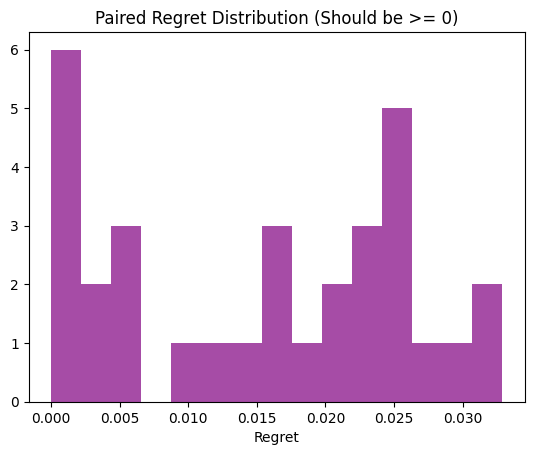

In [ ]:
# discrete single

# ============================================================
# 4. FIXED RIGOROUS EVALUATION (Paired Samples)
#    Run this after training to get accurate metrics.
# ============================================================

def rigorous_eval_paired(
    auction,
    mechanism_net,
    policy_net,
    params_mech,
    params_policy,
    num_eval_keys=32,    # Number of different random seeds (Tests)
    num_samples=256,     # Trajectories per key (for Profit/IR)
    num_probes=1024,     # Random strategies per key (for Regret)
    temperature=0.05
):
    print(f"\n{'='*60}")
    print(f"STARTING PAIRED EVALUATION (K={num_eval_keys})")
    print(f"{'='*60}")

    # --- HELPER: Paired Regret Calculation ---
    # This ensures Truthful and Policy runs face the EXACT same world.
    def compute_paired_regret_scan(key):
        # 1. Setup Keys
        # k_env: Determines the world (valuation changes)
        # k_pol: Determines policy randomness (if stochastic)
        # k_probe: Determines random probe strategies
        k_env, k_pol, k_probe = jax.random.split(key, 3)

        # Pre-generate the environment keys for the whole trajectory
        # This acts as the "Fixed World"
        env_keys_seq = jax.random.split(k_env, auction.num_horizons)

        # --- Shared Trajectory Runner ---
        # Takes a strategy function: (state, t, rng) -> report
        def run_trajectory(strategy_fn, strat_rng_key):

            def step(carry, inputs):
                state, cum_u = carry
                t, env_key = inputs

                # 1. Get Report (Strategy)
                rng_step = jax.random.fold_in(strat_rng_key, t) if strat_rng_key is not None else None
                report = strategy_fn(state, t, rng_step)

                # 2. Mechanism
                alloc, pay = mechanism_net.apply(params_mech, state, report, auction)
                # Slice to handle potential dummy buyers safely
                alloc = alloc[:auction.num_buyers]
                pay = pay[:auction.num_buyers]

                # 3. Utility (Track Buyer 0 for IC)
                # Note: We calculate utility against the TRUE type in state
                util = (state.current_type[0] * alloc[0] - pay[0]).squeeze()

                # 4. Transition (CRITICAL: Uses shared env_key)
                next_state = auction.get_next_state(state, report, alloc, env_key)

                return (next_state, cum_u + (auction.discount**t) * util), None

            # Init State (Deterministically from first env key to keep synced)
            s_init = auction.get_initial_state(env_keys_seq[0])
            (s_final, total_u), _ = jax.lax.scan(step, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys_seq))
            return total_u

        # --- Strategy A: Truthful ---
        def strat_truthful(state, t, rng):
            return state.current_type

        u_truth = run_trajectory(strat_truthful, None)

        # --- Strategy B: Learned Policy ---
        def strat_policy(state, t, rng):
            # Reconstruct belief for policy (simplified for robust check)
            b_state = auction.get_initial_belief_state(state)
            policy = DiffPolicy(policy_net, params_policy, temperature)
            return policy(b_state, auction, rng)

        u_policy = -1e9
        if params_policy is not None:
            u_policy = run_trajectory(strat_policy, k_pol)

        # --- Strategy C: Random Probes (The "Dumb" Attack) ---
        # Generate random fixed lie sequences for Buyer 0
        # Shape: (num_probes, horizons)
        probes = jax.random.randint(k_probe, (num_probes, auction.num_horizons), 0, auction.num_types)

        def eval_single_probe(probe_seq):
            def strat_probe(state, t, rng):
                # Always lie according to the pre-set probe sequence
                val_lie = auction.buyer_types[0, probe_seq[t]]
                return state.current_type.at[0].set(val_lie)
            return run_trajectory(strat_probe, None)

        u_best_probe = jnp.max(jax.vmap(eval_single_probe)(probes))

        # --- Calc Regret ---
        # Max(Policy, Probe) - Truth
        # Since World is fixed, u_truth is the valid baseline.
        regret = jnp.maximum(u_policy, u_best_probe) - u_truth
        return regret

    # --- HELPER: Profit & IR ---
    # (These don't strictly need pairing, but we use vmap for speed)
    @jax.jit
    def eval_metrics(key):
        k_prof, k_ir = jax.random.split(key, 2)
        mechanism = Mechanism(mechanism_net, params_mech)

        # Profit
        prof = AuctionSimulator.estimate_cumulative_profit(auction, mechanism, num_samples, k_prof)

        # IR Ex-Post (Bankruptcy Check)
        # 1. Sample States
        s_init_batch = AuctionSimulator.sample_init_state(auction, num_samples, k_ir)
        # 2. Run Trajectories
        def get_u(s, k):
            return AuctionSimulator.sample_cumulative_rewards(auction, s, mechanism, k)
        u_batch = jax.vmap(get_u)(s_init_batch, jax.random.split(k_ir, num_samples))
        # 3. Calc Violation: Mean of [Sum of ReLU(-u) per user]
        ir_viol = jnp.mean(jnp.sum(jax.nn.relu(-u_batch), axis=1))

        return prof, ir_viol

    # --- EXECUTION LOOP ---
    eval_keys = jax.random.split(jax.random.PRNGKey(8888), num_eval_keys)

    profits = []
    ir_viols = []
    regrets = []

    # JIT the regret checker
    jit_regret_check = jax.jit(compute_paired_regret_scan)

    for i, k in enumerate(eval_keys):
        k_met, k_reg = jax.random.split(k, 2)

        # 1. Metrics
        p, ir = eval_metrics(k_met)
        profits.append(float(p))
        ir_viols.append(float(ir))

        # 2. Regret (Paired)
        r = jit_regret_check(k_reg)
        regrets.append(float(r))

        if (i+1) % 5 == 0:
            print(f"  Processed {i+1}/{num_eval_keys}...")

    # --- REPORT ---
    stats = {
        "profit": np.mean(profits),
        "profit_std": np.std(profits),
        "ir_viol": np.mean(ir_viols),
        "ir_max": np.max(ir_viols),
        "regret": np.mean(regrets),
        "regret_std": np.std(regrets),
        "regret_max": np.max(regrets)
    }

    print(f"\n{'='*60}")
    print(f"FINAL PAIRED RESULTS")
    print(f"{'='*60}")
    print(f"PROFIT:       {stats['profit']:.4f} ± {stats['profit_std']:.4f}")
    print(f"IR VIOLATION: {stats['ir_viol']:.4f} (Max: {stats['ir_max']:.4f})")
    print(f"REGRET (IC):  {stats['regret']:.4f} ± {stats['regret_std']:.4f}")
    print(f"  Max Regret: {stats['regret_max']:.4f} (Worst vulnerability found)")
    print(f"{'='*60}")

    return stats, regrets

# --- RUN IT ---
stats, regrets_list = rigorous_eval_paired(
    auction,
    mechanism_network,
    policy_network,
    final_theta,   # From your previous training
    final_policy,  # From your previous training
    num_eval_keys=32,
    num_samples=512,
    num_probes=2048
)

# Optional Plot
plt.hist(regrets_list, bins=15, alpha=0.7, color='purple')
plt.title("Paired Regret Distribution (Should be >= 0)")
plt.xlabel("Regret")
plt.show()

--- STARTING ANNEALED CONTINUOUS TRAINING (FINAL FIXED) ---
Epoch  | Profit    | Reg(S)    | Reg(P)    | IR        | Beta
0      | 14.7785   | 2.8889    | 0.3161    | 10.0453   | 0.0
100    | 9.7035    | 0.0002    | 0.0000    | 0.0120    | 10.0
200    | 8.4970    | 0.0006    | 0.0002    | 0.0000    | 10.0
300    | 9.4496    | 0.0022    | 0.0010    | 0.0578    | 10.0
400    | 9.5512    | 0.0000    | 0.0000    | 0.0000    | 10.0
500    | 10.0819   | 0.0052    | 0.0000    | 0.0592    | 10.0
600    | 8.9153    | 0.0014    | 0.0002    | 0.0000    | 10.0
700    | 10.3523   | 0.0005    | 0.0008    | 0.0143    | 10.0
800    | 9.8339    | 0.0025    | 0.0000    | 0.0005    | 10.0
900    | 10.1334   | 0.0002    | 0.0000    | 0.0186    | 10.0
1000   | 9.4323    | 0.0004    | 0.0000    | 0.0069    | 10.0
1100   | 9.5408    | 0.0007    | 0.0004    | 0.0000    | 10.0
1200   | 9.9171    | 0.0000    | 0.0000    | 0.0027    | 10.0
1300   | 9.7552    | 0.0000    | 0.0000    | 0.0000    | 10.0
1400   | 10

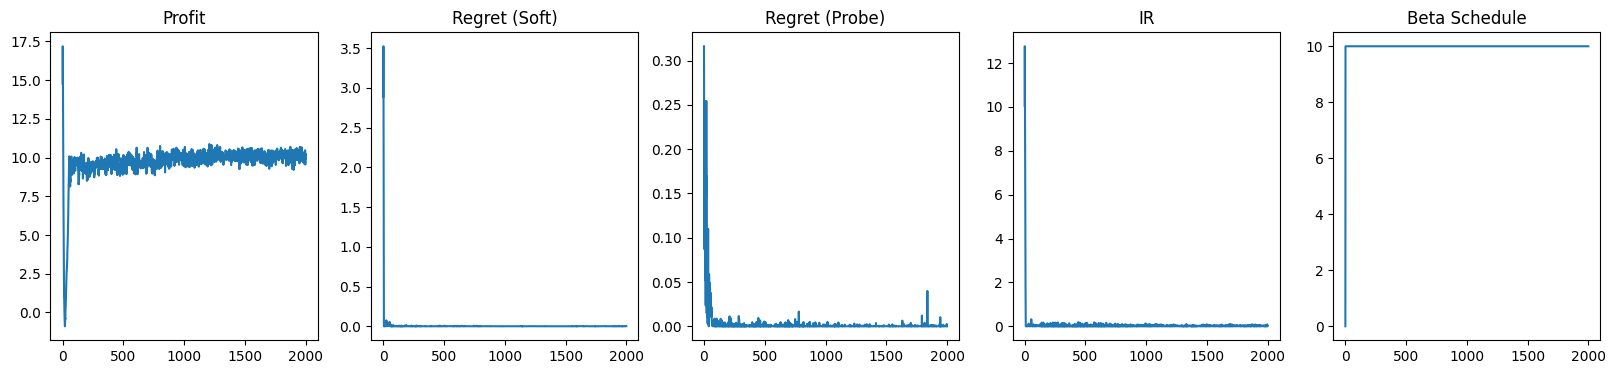


STARTING PAIRED EVALUATION (K=32)
  Processed 1/32...
  Processed 6/32...
  Processed 11/32...
  Processed 16/32...
  Processed 21/32...
  Processed 26/32...
  Processed 31/32...

FINAL RESULTS
Profit:      9.9293 ± 0.0824
IR Viol:     0.0030
Regret Avg:  0.0029
Regret Max:  0.0195 (Worst observed deviation)


In [ ]:
# cont single
import os
import json
import time
import pickle
import shutil
import functools
from typing import Any, Dict, List, Tuple

import jax
import jax.numpy as jnp
import haiku as hk
import optax
import numpy as np
import matplotlib.pyplot as plt
from flax import struct

# Set seed
SEED = 42

# ==============================================================================
# 1. SETUP: CLASSES & SIMULATOR
# ==============================================================================

@struct.dataclass
class State:
    time_step: int
    allocation_history: jnp.ndarray
    current_type: jnp.ndarray
    report_history: jnp.ndarray

    def replace_state(self, new_time_step, new_allocation_history, new_current_type, new_report_history):
        return self.replace(time_step=new_time_step, allocation_history=new_allocation_history,
                            current_type=new_current_type, report_history=new_report_history)

@struct.dataclass
class BeliefState:
    time_step: int
    allocation_history: jnp.ndarray
    beliefs: jnp.ndarray # Not used in bounded policy directly but kept for compatibility
    report_history: jnp.ndarray
    # Add embeddings if your specific architecture needs them
    pub_embed: jnp.ndarray = struct.field(default=None)
    priv_embeds: jnp.ndarray = struct.field(default=None)

@struct.dataclass
class BanditAuction:
    num_horizons: int = struct.field(pytree_node=False)
    num_buyers: int = struct.field(pytree_node=False)
    num_types: int = struct.field(pytree_node=False)
    num_goods: int = struct.field(pytree_node=False)
    init_state_function: Any = struct.field(pytree_node=False)
    init_belief_state_function: Any = struct.field(pytree_node=False)
    get_transition_prob: Any = struct.field(pytree_node=False)
    transition_function: Any = struct.field(pytree_node=False)
    discount: float = struct.field(pytree_node=False)
    buyer_types: jnp.ndarray = struct.field(pytree_node=False) # Not used for continuous
    type_profiles: List[jnp.ndarray] = struct.field(pytree_node=False)
    # Continuous specific fields
    sample_types_fn: Any = struct.field(pytree_node=False)
    types_low: jnp.ndarray = struct.field(pytree_node=False)
    types_high: jnp.ndarray = struct.field(pytree_node=False)
    d_pub: int = struct.field(pytree_node=False, default=64)
    d_priv: int = struct.field(pytree_node=False, default=128)

    def get_initial_state(self, key):
        return self.init_state_function(self, key)

    def get_initial_belief_state(self, state):
        return self.init_belief_state_function(self, state)

    def get_next_state(self, state, report, allocation, key):
        time_step = state.time_step
        new_time_step = time_step + 1
        new_alloc_hist = state.allocation_history.at[time_step].set(allocation)
        new_type = self.transition_function(self, time_step, state.current_type, new_alloc_hist, key)
        new_report_hist = state.report_history.at[time_step].set(report)
        return state.replace_state(new_time_step, new_alloc_hist, new_type, new_report_hist)

# --- Samplers ---
def make_gaussian_sampler(mean, std):
    mean, std = jnp.asarray(mean), jnp.asarray(std)
    def sample(key):
        return mean + std * jax.random.normal(key, shape=mean.shape)
    return sample

# --- Initialization ---
def auction_init_state(auction, key):
    initial_types = auction.sample_types_fn(key)
    return State(0, jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
                 initial_types, jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)))

def auction_init_belief_state(auction, state):
    # Dummy embedding initialization for continuous nets
    c0 = jnp.zeros((auction.d_pub,))
    h0 = jnp.zeros((auction.num_buyers, auction.d_priv))
    # Inject current type into h0 if architecture requires it
    h0 = h0.at[:, :auction.num_goods].set(state.current_type)

    return BeliefState(0, jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
                       jnp.zeros((1,)), # Dummy discrete beliefs
                       jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
                       pub_embed=c0, priv_embeds=h0)

# --- Transition (Continuous) ---
def _normalize_to_unit(t, low, high, eps=1e-6):
    width = jnp.maximum(high - low, 1e-12)
    p = (t - low) / width
    return jnp.clip(p, eps, 1.0 - eps), width

def _logit(p): return jnp.log(p) - jnp.log1p(-p)
def _inv_logit(s): return jax.nn.sigmoid(s)

def auction_transition_fn_bounded(auction, time_step, types, allocation_history, key):
    # Simplified Logit-Normal Transition
    types_low, types_high = auction.types_low, auction.types_high
    sigma = 0.1 # Fixed noise for demo

    p_t, width = _normalize_to_unit(types, types_low, types_high)
    s_t = _logit(p_t)
    noise = jax.random.normal(key, shape=types.shape)
    s_tp1 = s_t + sigma * noise
    p_tp1 = _inv_logit(s_tp1)
    return types_low + width * p_tp1

def create_bandit_auction_continuous():
    B, G = 2, 1 # 2 Buyers, 1 Item
    mean = jnp.ones((B, G)) * 2.5
    std = jnp.ones((B, G)) * 0.5
    low = jnp.zeros((B, G))
    high = jnp.ones((B, G)) * 5.0

    return BanditAuction(
        num_horizons=5, num_buyers=B, num_types=0, num_goods=G,
        init_state_function=auction_init_state,
        init_belief_state_function=auction_init_belief_state,
        get_transition_prob=None,
        transition_function=auction_transition_fn_bounded,
        discount=0.9,
        buyer_types=None, type_profiles=[],
        sample_types_fn=make_gaussian_sampler(mean, std),
        types_low=low, types_high=high
    )

auction = create_bandit_auction_continuous()

# --- Networks ---

def _mechanism_network(state: State, report: jnp.ndarray, auction: BanditAuction):
    inputs = jnp.concatenate([state.current_type.flatten(), report.flatten()])
    hidden = hk.Sequential([hk.Linear(128), jax.nn.relu, hk.Linear(64), jax.nn.relu])(inputs)

    # Alloc: (B+1, G)
    logits = hk.Linear((auction.num_buyers + 1) * auction.num_goods)(hidden)
    logits = logits.reshape(auction.num_buyers + 1, auction.num_goods)
    probs = jax.nn.softmax(logits, axis=0)

    # Pay: (B,)
    pay = hk.Linear(auction.num_buyers)(hidden)
    return probs, pay

class LogitProtoResidualHead(hk.Module):
    # Added cproj_init_std to __init__
    def __init__(self, d_priv, d_pub, G, hidden=128, residual_init_std=0.0, cproj_init_std=0.0, stop_grad_truth=True, eps=1e-6, name=None):
        super().__init__(name=name)
        self.G = G
        self.trunk = hk.nets.MLP([hidden, hidden], activate_final=True)
        self.res_std = residual_init_std
        self.cproj_std = cproj_init_std
        self.stop = stop_grad_truth
        self.eps = eps

    def __call__(self, belief_state, types_low, types_high):
        H = belief_state.priv_embeds # (B, d_priv)
        c = belief_state.pub_embed   # (d_pub)
        B = H.shape[0]

        # Truthful Prototype (First G dims of H are current type)
        H_type = H[:, :self.G]
        if self.stop: H_type = jax.lax.stop_gradient(H_type)

        # Residual
        c_expanded = jnp.broadcast_to(c, (B, c.shape[0]))
        x = jnp.concatenate([H, c_expanded], axis=-1)
        z = self.trunk(x)

        # Zero-init last layer
        w_init = hk.initializers.RandomNormal(self.res_std) if self.res_std > 0 else hk.initializers.Constant(0.)
        Delta = hk.Linear(self.G, w_init=w_init, b_init=hk.initializers.Constant(0.))(z)

        # Logit Space Math
        p0, width = _normalize_to_unit(H_type, types_low, types_high, eps=self.eps)
        s0 = _logit(p0)
        s = s0 + Delta
        out = types_low + width * _inv_logit(s)
        return out

def build_bounded_policy_net(d_priv, d_pub, G, hidden=128, residual_init_std=0.0, cproj_init_std=0.0, **kwargs):
    def f(belief_state, auction):
        # Pass all args correctly
        head = LogitProtoResidualHead(
            d_priv, d_pub, G, hidden,
            residual_init_std=residual_init_std,
            cproj_init_std=cproj_init_std,
            **kwargs
        )
        return head(belief_state, auction.types_low, auction.types_high)
    return hk.without_apply_rng(hk.transform(f))

# --- Wrappers ---
@struct.dataclass
class Mechanism:
    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params
    def __call__(self, state, report, auction):
        alloc, pay = self.network.apply(self.params, state, report, auction)
        return alloc[:-1], pay

@struct.dataclass
class BoundedContPolicy:
    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params
    def __call__(self, belief_state, auction, key=None):
        return self.network.apply(self.params, belief_state, auction)

class AuctionSimulator:
    @staticmethod
    def sample_init_state(auction, num, key):
        return jax.vmap(auction.get_initial_state)(jax.random.split(key, num))

    @staticmethod
    def estimate_cumulative_profit(auction, mech, num, key):
        def run(k):
            s = auction.get_initial_state(k)
            # Use fixed env keys
            k_env = jax.random.split(k, 2)[0]
            env_keys = jax.random.split(k_env, auction.num_horizons)

            def step(carry, x):
                s, p = carry; t, ek = x
                alloc, pay = mech(s, s.current_type, auction)
                ns = auction.get_next_state(s, s.current_type, alloc, ek)
                return (ns, p + (auction.discount**t)*jnp.sum(pay)), None

            # [FIXED UNPACKING]
            (sf, tot_p), _ = jax.lax.scan(step, (s, 0.0), (jnp.arange(auction.num_horizons), env_keys))
            return tot_p
        return jnp.mean(jax.vmap(run)(jax.random.split(key, num)))

    @staticmethod
    def estimate_cumulative_regret(auction, mech, policy, num, key):
        # Soft regret for training gradient
        def run(k):
            s_init = auction.get_initial_state(k)
            k_env = jax.random.split(k, 2)[0]
            env_keys = jax.random.split(k_env, auction.num_horizons)

            # Truth
            def step_t(carry, x):
                s, u = carry; t, ek = x
                alloc, pay = mech(s, s.current_type, auction)
                # Scalar utility (Buyer 0)
                val = jnp.sum(s.current_type[0] * alloc[0])
                return (auction.get_next_state(s, s.current_type, alloc, ek), u + (auction.discount**t)*(val-pay[0])), None
            (sf_t, u_t), _ = jax.lax.scan(step_t, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys))

            # Policy
            def step_p(carry, x):
                s, u = carry; t, ek = x
                b = auction.get_initial_belief_state(s)
                rep = policy(b, auction) # Deterministic
                alloc, pay = mech(s, rep, auction)
                val = jnp.sum(s.current_type[0] * alloc[0])
                return (auction.get_next_state(s, rep, alloc, ek), u + (auction.discount**t)*(val-pay[0])), None
            (sf_p, u_p), _ = jax.lax.scan(step_p, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys))

            return u_p - u_t
        return jnp.mean(jax.vmap(run)(jax.random.split(key, num)))

# ==============================================================================
# 2. TRAINING LOOP (ANNEALED + HARDENED)
# ==============================================================================

def train_method3_annealed(
    auction, mechanism_net, policy_net,
    num_outer_epochs=5000,
    lr_theta=1e-3,       # Higher LR to explore profit quickly
    lr_w=1e-3,
    num_inner_steps=20,
    final_beta_ic=50.0,  # High final penalty
    final_beta_ir=50.0,
    warmup_epochs=1000,  # Schedule: 0 -> final_beta over 1000 epochs
    num_samples=64,
    num_train_probes=128,
    print_iter=100
):
    prng = hk.PRNGSequence(SEED)

    # Init
    s_init = auction.get_initial_state(next(prng))
    params_m = mechanism_net.init(next(prng), s_init, s_init.current_type, auction)
    opt_m = optax.adam(lr_theta)
    state_m = opt_m.init(params_m)

    b_init = auction.get_initial_belief_state(s_init)
    params_p = policy_net.init(next(prng), b_init, auction)
    opt_p = optax.adam(lr_w)
    state_p = opt_p.init(params_p)

    # --- Schedule ---
    def get_betas(epoch):
        progress = jnp.clip(epoch / warmup_epochs, 0.0, 1.0)
        return progress * final_beta_ic, progress * final_beta_ir

    # --- HELPER: Fast Probe Regret for Training ---
    def get_probe_regret_batch(theta, key):
        # Sample uniform probes
        k_uni = jax.random.split(key, num_train_probes)
        def sample_uniform(k):
            u = jax.random.uniform(k, shape=auction.types_low.shape)
            return auction.types_low + (auction.types_high - auction.types_low) * u
        probe_vals = jax.vmap(sample_uniform)(k_uni)

        k_env, k_run = jax.random.split(key, 2)
        env_keys = jax.random.split(k_env, auction.num_horizons)
        s_init_world = auction.get_initial_state(env_keys[0])

        # Truthful
        def run_truthful(carry, x):
            s, u = carry; t, e_k = x
            rep = s.current_type
            alloc_probs, pay = mechanism_net.apply(theta, s, rep, auction)
            alloc, pay = alloc_probs[:auction.num_buyers], pay[:auction.num_buyers]
            # [FIXED UNPACKING]
            val_goods = jnp.sum(s.current_type[0] * alloc[0])
            util = val_goods - pay[0]
            ns = auction.get_next_state(s, rep, alloc, e_k)
            return (ns, u + (auction.discount**t)*util), None

        (s_final, u_truth), _ = jax.lax.scan(run_truthful, (s_init_world, 0.0), (jnp.arange(auction.num_horizons), env_keys))

        # Probes
        def run_probe(val_lie):
            def step(carry, x):
                s, u = carry; t, e_k = x
                # Buyer 0 lies
                rep = s.current_type.at[0].set(val_lie[0])
                alloc_probs, pay = mechanism_net.apply(theta, s, rep, auction)
                alloc, pay = alloc_probs[:auction.num_buyers], pay[:auction.num_buyers]
                val_goods = jnp.sum(s.current_type[0] * alloc[0])
                util = val_goods - pay[0]
                ns = auction.get_next_state(s, rep, alloc, e_k)
                return (ns, u + (auction.discount**t)*util), None
            (s_final, u_probe), _ = jax.lax.scan(step, (s_init_world, 0.0), (jnp.arange(auction.num_horizons), env_keys))
            return u_probe

        u_probes = jax.vmap(run_probe)(probe_vals)
        best_probe_regret = jnp.max(u_probes) - u_truth
        return jnp.maximum(0.0, best_probe_regret)

    # --- OUTER LOSS (Hardened + Annealed) ---
    def loss_outer_annealed(theta, p_params, key, temp, b_ic, b_ir):
        k1, k2, k3, k4 = jax.random.split(key, 4)

        # 1. Profit
        mech = Mechanism(mechanism_net, theta)
        prof = AuctionSimulator.estimate_cumulative_profit(auction, mech, num_samples, k1)

        # 2. Regret A: Gradient Policy (Soft)
        def get_soft_regret(k_traj):
            k_env, k_pol = jax.random.split(k_traj, 2)
            env_keys = jax.random.split(k_env, auction.num_horizons)
            s_init = auction.get_initial_state(env_keys[0])

            def step_t(carry, x):
                s, u = carry; t, ek = x
                alloc, pay = mechanism_net.apply(theta, s, s.current_type, auction)
                alloc, pay = alloc[:auction.num_buyers], pay[:auction.num_buyers]
                val = jnp.sum(s.current_type[0] * alloc[0])
                util = val - pay[0]
                return (auction.get_next_state(s, s.current_type, alloc, ek), u + (auction.discount**t)*util), None
            (sf_t, u_true), _ = jax.lax.scan(step_t, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys))

            def step_p(carry, x):
                s, u = carry; t, ek = x
                pol = BoundedContPolicy(policy_net, p_params)
                b = auction.get_initial_belief_state(s)
                rep = pol(b, auction)
                alloc, pay = mechanism_net.apply(theta, s, rep, auction)
                alloc, pay = alloc[:auction.num_buyers], pay[:auction.num_buyers]
                val = jnp.sum(s.current_type[0] * alloc[0])
                util = val - pay[0]
                return (auction.get_next_state(s, rep, alloc, ek), u + (auction.discount**t)*util), None
            (sf_p, u_pol), _ = jax.lax.scan(step_p, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys))
            return u_pol - u_true

        reg_soft = jnp.mean(jax.vmap(get_soft_regret)(jax.random.split(k2, num_samples)))
        reg_soft = jnp.maximum(0.0, reg_soft)

        # 3. Regret B: Probe
        reg_probe = jnp.mean(jax.vmap(lambda k: get_probe_regret_batch(theta, k))(jax.random.split(k3, 4)))

        # 4. IR
        def get_ir(k):
            s_init = auction.get_initial_state(k)
            k_env = jax.random.split(k, 2)[0]
            env_keys = jax.random.split(k_env, auction.num_horizons)
            def step(carry, x):
                s, u = carry; t, ek = x
                alloc, pay = mech(s, s.current_type, auction)
                val = jnp.sum(s.current_type * alloc, axis=1) # (B,)
                return (auction.get_next_state(s, s.current_type, alloc, ek), u + (auction.discount**t)*(val-pay)), None

            (sf, u_tot), _ = jax.lax.scan(step, (s_init, jnp.zeros(auction.num_buyers)), (jnp.arange(auction.num_horizons), env_keys))
            return jnp.sum(jax.nn.relu(-u_tot))

        ir = jnp.mean(jax.vmap(get_ir)(jax.random.split(k4, num_samples)))

        # Total Loss
        reg_robust = jnp.maximum(reg_soft, reg_probe)
        loss = -prof + b_ic * reg_robust + b_ir * ir
        return loss, (prof, reg_soft, reg_probe, ir)

    @jax.jit
    def outer_step(theta, p_params, opt_state, key, temp, b_ic, b_ir):
        (loss, aux), grads = jax.value_and_grad(loss_outer_annealed, has_aux=True)(theta, p_params, key, temp, b_ic, b_ir)
        updates, opt_state = opt_m.update(grads, opt_state, theta)
        return loss, aux, optax.apply_updates(theta, updates), opt_state

    # --- INNER STEP ---
    @jax.jit
    def update_policy(p_params, theta, opt_state, key):
        def loss(p):
            m = Mechanism(mechanism_net, theta)
            pol = BoundedContPolicy(policy_net, p)
            return AuctionSimulator.estimate_cumulative_regret(auction, m, pol, num_samples, key)
        (reg, grads) = jax.value_and_grad(loss)(p_params)
        grads = jax.tree_util.tree_map(lambda x: -x, grads)
        updates, opt_state = opt_p.update(grads, opt_state, p_params)
        return reg, optax.apply_updates(p_params, updates), opt_state

    # --- LOOP ---
    logs = {"loss": [], "profit": [], "regret_soft": [], "regret_probe": [], "ir": [], "beta": []}
    print(f"{'Epoch':<6} | {'Profit':<9} | {'Reg(S)':<9} | {'Reg(P)':<9} | {'IR':<9} | {'Beta'}")

    for epoch in range(num_outer_epochs):
        temp = 1.0 # Temperature doesn't matter for deterministic bounded policy
        b_ic, b_ir = get_betas(epoch)

        for _ in range(num_inner_steps):
            k_in = next(prng)
            _, params_p, state_p = update_policy(params_p, params_m, state_p, k_in)

        k_out = next(prng)
        loss, (prof, reg_s, reg_p, ir), params_m, state_m = outer_step(params_m, params_p, state_m, k_out, temp, b_ic, b_ir)

        logs["loss"].append(float(loss))
        logs["profit"].append(float(prof))
        logs["regret_soft"].append(float(reg_s))
        logs["regret_probe"].append(float(reg_p))
        logs["ir"].append(float(ir))
        logs["beta"].append(float(b_ic))

        if epoch % print_iter == 0:
            print(f"{epoch:<6d} | {float(prof):<9.4f} | {float(reg_s):<9.4f} | {float(reg_p):<9.4f} | {float(ir):<9.4f} | {float(b_ic):.1f}")

    return params_m, params_p, logs

# ==============================================================================
# 3. PAIRED EVALUATION SCRIPT (FIXED ARGS + UNPACKING + CLAMPING)
# ==============================================================================
def rigorous_eval_continuous(
    auction, mechanism_net, policy_net, params_mech, params_policy,
    num_keys=32, num_samples=256
):
    print(f"\n{'='*60}")
    print(f"STARTING PAIRED EVALUATION (K={num_keys})")
    print(f"{'='*60}")

    def compute_paired_regret(key):
        k_env, k_pol = jax.random.split(key, 2)
        env_keys_seq = jax.random.split(k_env, auction.num_horizons)

        # Shared Runner
        def run_trajectory(strategy_fn):
            def step(carry, inputs):
                state, cum_u = carry; t, env_key = inputs
                report = strategy_fn(state, t)
                alloc, pay = mechanism_net.apply(params_mech, state, report, auction)
                alloc = alloc[:auction.num_buyers]; pay = pay[:auction.num_buyers]
                val = jnp.sum(state.current_type[0] * alloc[0]) # Buyer 0
                util = val - pay[0]
                next_state = auction.get_next_state(state, report, alloc, env_key)
                return (next_state, cum_u + (auction.discount**t)*util), None

            s_init = auction.get_initial_state(env_keys_seq[0])
            # [FIXED UNPACKING]
            (s_final, total_u), _ = jax.lax.scan(step, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys_seq))
            return total_u

        # Truthful
        u_truth = run_trajectory(lambda s, t: s.current_type)

        # Policy
        def strat_policy(s, t):
            b = auction.get_initial_belief_state(s)
            # [FIXED ARGS]
            return policy_net.apply(params_policy, b, auction)
        u_pol = run_trajectory(strat_policy)

        # [FIXED NEGATIVE REGRET]
        return jnp.maximum(0.0, u_pol - u_truth)

    @jax.jit
    def eval_batch(key):
        k_prof, k_reg = jax.random.split(key, 2)
        # Profit / IR (Standard sample)
        mech = Mechanism(mechanism_net, params_mech)
        prof = AuctionSimulator.estimate_cumulative_profit(auction, mech, num_samples, k_prof)

        def get_ir(k):
            s_init = auction.get_initial_state(k)
            k_env = jax.random.split(k, 2)[0]
            env_keys = jax.random.split(k_env, auction.num_horizons)
            def step(carry, x):
                s, u = carry; t, ek = x
                alloc, pay = mech(s, s.current_type, auction)
                val = jnp.sum(s.current_type * alloc, axis=1)
                return (auction.get_next_state(s, s.current_type, alloc, ek), u + (auction.discount**t)*(val-pay)), None

            # [FIXED UNPACKING]
            (sf, u_tot), _ = jax.lax.scan(step, (s_init, jnp.zeros(auction.num_buyers)), (jnp.arange(auction.num_horizons), env_keys))
            return jnp.sum(jax.nn.relu(-u_tot))

        ir = jnp.mean(jax.vmap(get_ir)(jax.random.split(k_prof, num_samples)))

        # Regret (Paired)
        regs = jax.vmap(compute_paired_regret)(jax.random.split(k_reg, num_samples))
        return prof, ir, jnp.mean(regs), jnp.max(regs)

    keys = jax.random.split(jax.random.PRNGKey(999), num_keys)
    profits, irs, mean_regs, max_regs = [], [], [], []

    for i, k in enumerate(keys):
        p, ir, r_avg, r_max = eval_batch(k)
        profits.append(float(p))
        irs.append(float(ir))
        mean_regs.append(float(r_avg))
        max_regs.append(float(r_max))
        if i % 5 == 0: print(f"  Processed {i+1}/{num_keys}...")

    print(f"\n{'='*60}")
    print(f"FINAL RESULTS")
    print(f"{'='*60}")
    print(f"Profit:      {np.mean(profits):.4f} ± {np.std(profits):.4f}")
    print(f"IR Viol:     {np.mean(irs):.4f}")
    print(f"Regret Avg:  {np.mean(mean_regs):.4f}")
    print(f"Regret Max:  {np.max(max_regs):.4f} (Worst observed deviation)")
    print(f"{'='*60}")
    return profits, mean_regs

# =========================================================
# 4. EXECUTION
# =========================================================
if __name__ == "__main__":
    print("--- STARTING ANNEALED CONTINUOUS TRAINING (FINAL FIXED) ---")

    mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
    policy_network = build_bounded_policy_net(
        d_priv=auction.d_priv, d_pub=auction.d_pub, G=auction.num_goods,
        hidden=128, residual_init_std=1.0, cproj_init_std=0.0
    )

    final_theta, final_policy_w, logs = train_method3_annealed(
        auction, mechanism_network, policy_network,
        num_outer_epochs=2000,
        lr_theta=1e-3,
        lr_w=1e-3,
        num_train_probes=128,
        final_beta_ic=10.0,
        final_beta_ir=10.0,
        warmup_epochs=1,
        print_iter=100
    )

    # Plot
    plt.figure(figsize=(20, 4))
    plt.subplot(1,5,1); plt.plot(logs['profit']); plt.title('Profit')
    plt.subplot(1,5,2); plt.plot(logs['regret_soft']); plt.title('Regret (Soft)')
    plt.subplot(1,5,3); plt.plot(logs['regret_probe']); plt.title('Regret (Probe)')
    plt.subplot(1,5,4); plt.plot(logs['ir']); plt.title('IR')
    plt.subplot(1,5,5); plt.plot(logs['beta']); plt.title('Beta Schedule')
    plt.show()

    # Eval
    _ = rigorous_eval_continuous(auction, mechanism_network, policy_network, final_theta, final_policy_w)

--- STARTING CONTINUOUS + MULTI-ITEM Penalty Method ---
Num Goods: 2
Epoch 0   : Profit=-5.3732 | Regret=2.5136 | IR=0.0000 | Loss=55.6455
Epoch 50  : Profit=-3.5889 | Regret=0.0792 | IR=0.0000 | Loss=5.1737
Epoch 100 : Profit=1.5865 | Regret=-0.0336 | IR=0.0000 | Loss=-1.5865
Epoch 150 : Profit=4.0248 | Regret=-1.4555 | IR=0.0000 | Loss=-4.0248
Epoch 200 : Profit=7.9902 | Regret=0.0242 | IR=0.0000 | Loss=-7.5068
Epoch 250 : Profit=12.6654 | Regret=0.0162 | IR=0.0018 | Loss=-12.3053
Epoch 300 : Profit=15.7565 | Regret=0.0223 | IR=0.0087 | Loss=-15.1366
Epoch 350 : Profit=17.0584 | Regret=0.0290 | IR=0.0399 | Loss=-15.6802
Epoch 400 : Profit=17.6603 | Regret=0.0127 | IR=0.0097 | Loss=-17.2111
Epoch 450 : Profit=18.2008 | Regret=0.0107 | IR=0.0081 | Loss=-17.8249
Epoch 500 : Profit=18.4762 | Regret=0.0244 | IR=0.0036 | Loss=-17.9165
Epoch 550 : Profit=18.4832 | Regret=0.0047 | IR=0.0062 | Loss=-18.2666
Epoch 600 : Profit=18.6439 | Regret=0.0046 | IR=0.0028 | Loss=-18.4972
Epoch 650 : Pro

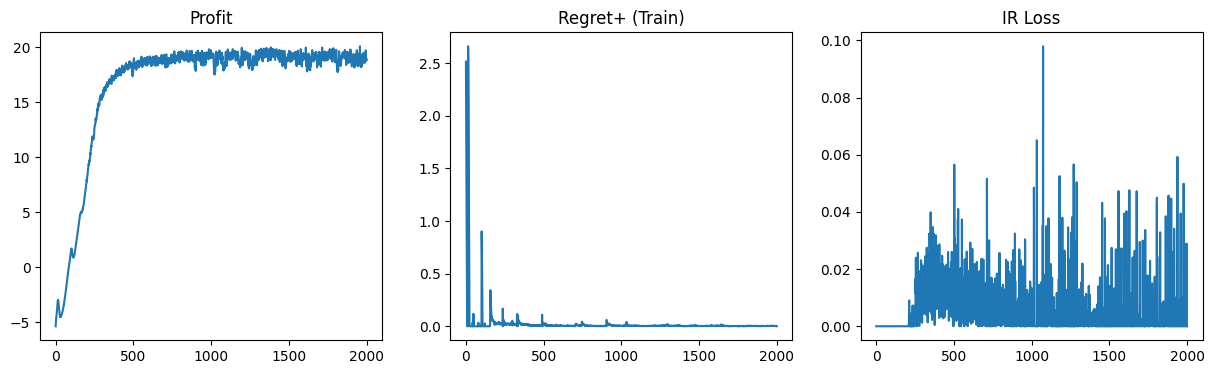


STARTING PAIRED EVALUATION (K=32)
  Processed 1/32...
  Processed 6/32...
  Processed 11/32...
  Processed 16/32...
  Processed 21/32...
  Processed 26/32...
  Processed 31/32...

FINAL RESULTS
Profit:      18.8398 ± 0.1180
IR Viol:     0.0000
Regret Avg:  0.0037
Regret Max:  0.2935


In [ ]:
# continuous multi
import jax
import jax.numpy as jnp
import haiku as hk
import optax
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. TRAIN: Penalty Method (Continuous + Multi-Item)
# =========================================================
def penalty_nested_GD_continuous(
    auction,
    mechanism_network,
    policy_network,
    num_outer_epochs: int = 2000,
    outer_steps_per_epoch: int = 1,
    lr_theta: float = 1e-4,
    num_inner_steps: int = 300,
    lr_w: float = 1e-3,
    num_samples: int = 64,
    beta_ic: float = 10.0,
    beta_ir: float = 10.0,
    print_iter: int = 50,
):
    prng = hk.PRNGSequence(SEED)

    # --- Initialization ---
    init_state = auction.get_initial_state(next(prng))
    mechanism_params = mechanism_network.init(next(prng), init_state, jnp.zeros((auction.num_buyers, auction.num_goods)), auction)

    init_belief = auction.get_initial_belief_state(init_state)
    policy_params = policy_network.init(next(prng), init_belief, auction)

    # --- Optimizers ---
    theta_opt = optax.adam(lr_theta)
    theta_opt_state = theta_opt.init(mechanism_params)
    w_opt = optax.adam(lr_w)
    w_opt_state = w_opt.init(policy_params)

    # --- Estimators ---
    @jax.jit
    def cumulative_regret(mechanism_params, policy_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = BoundedContPolicy(policy_network, policy_params)
        return AuctionSimulator.estimate_cumulative_regret(
            auction, mechanism, policy, num_samples, key
        )

    @jax.jit
    def cumulative_profit(mechanism_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        return AuctionSimulator.estimate_cumulative_profit(
            auction, mechanism, num_samples, key
        )

    @jax.jit
    def ir_loss(mechanism_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        # We need a batch of trajectories to check bankruptcy
        # Re-using simulator logic but applying ReLU for correct IR definition
        def get_traj_ir(k):
            s_init = auction.get_initial_state(k)
            # Fix env key for consistency within trajectory
            k_env = jax.random.split(k, 2)[0]
            env_keys = jax.random.split(k_env, auction.num_horizons)

            def step(carry, x):
                s, u = carry; t, ek = x
                alloc, pay = mechanism(s, s.current_type, auction)
                # Value = Sum over goods (axis=-1)
                val = jnp.sum(s.current_type * alloc, axis=-1)
                # Utility = Value - Payment
                util = val - pay
                ns = auction.get_next_state(s, s.current_type, alloc, ek)
                return (ns, u + (auction.discount**t)*util), None

            # Unpack scan correctly: (final_state, total_utility)
            (sf, u_tot), _ = jax.lax.scan(step, (s_init, jnp.zeros(auction.num_buyers)), (jnp.arange(auction.num_horizons), env_keys))
            # Loss = Sum of ReLU(-Utility) (only penalize negative utility)
            return jnp.sum(jax.nn.relu(-u_tot))

        return jnp.mean(jax.vmap(get_traj_ir)(jax.random.split(key, num_samples)))

    # --- Inner Loop ---
    @jax.jit
    def inner_step(mechanism_params, policy_params, w_opt_state, key):
        reg, grad_w = jax.value_and_grad(cumulative_regret, argnums=1)(
            mechanism_params, policy_params, key
        )
        grad_w_ascent = jax.tree_util.tree_map(lambda g: -g, grad_w)
        updates, w_opt_state = w_opt.update(grad_w_ascent, w_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, updates)
        return reg, policy_params, w_opt_state

    # --- Outer Loop ---
    @jax.jit
    def outer_step(mechanism_params, theta_opt_state, policy_params_star, key):
        k1, k2, k3 = jax.random.split(key, 3)

        def loss_fn(theta):
            reg = cumulative_regret(theta, policy_params_star, k1)
            prof = cumulative_profit(theta, k2)
            ir = ir_loss(theta, k3)
            reg_plus = jnp.maximum(0.0, reg)
            # Loss = -Profit + Penalties
            loss = -prof + beta_ic * reg_plus + beta_ir * ir
            return loss, (reg, reg_plus, prof, ir)

        (loss, aux), grad_theta = jax.value_and_grad(loss_fn, has_aux=True)(mechanism_params)
        updates, theta_opt_state = theta_opt.update(grad_theta, theta_opt_state, mechanism_params)
        mechanism_params = optax.apply_updates(mechanism_params, updates)
        return loss, aux, mechanism_params, theta_opt_state

    logs = {"loss": [], "profit": [], "regret": [], "regret_plus": [], "ir_loss": []}

    # --- Training ---
    for outer_epoch in range(num_outer_epochs):
        # 1. Inner Oracle
        curr_pol = policy_params
        curr_opt = w_opt_state
        for _ in range(num_inner_steps):
            k_in = next(prng)
            _, curr_pol, curr_opt = inner_step(mechanism_params, curr_pol, curr_opt, k_in)

        policy_params = curr_pol
        w_opt_state = curr_opt

        # 2. Outer Update
        for _ in range(outer_steps_per_epoch):
            k_out = next(prng)
            loss, (reg, reg_plus, prof, ir), mechanism_params, theta_opt_state = outer_step(
                mechanism_params, theta_opt_state, policy_params, k_out
            )

        logs["loss"].append(float(loss))
        logs["profit"].append(float(prof))
        logs["regret"].append(float(reg))
        logs["regret_plus"].append(float(reg_plus))
        logs["ir_loss"].append(float(ir))

        if outer_epoch % print_iter == 0:
            print(f"Epoch {outer_epoch:<4}: Profit={prof:.4f} | Regret={reg:.4f} | IR={ir:.4f} | Loss={loss:.4f}")

    trained_mech = Mechanism(mechanism_network, mechanism_params)
    trained_policy = BoundedContPolicy(policy_network, policy_params)

    return logs, trained_mech, trained_policy, mechanism_params, policy_params


# =========================================================
# 2. EVAL: Rigorous Paired Evaluation (Corrected)
# =========================================================
def rigorous_eval_continuous(
    auction, mechanism_net, policy_net, params_mech, params_policy,
    num_keys=32, num_samples=256
):
    print(f"\n{'='*60}")
    print(f"STARTING PAIRED EVALUATION (K={num_keys})")
    print(f"{'='*60}")

    # Helper to calculate regret on ONE paired trajectory
    def compute_paired_regret(key):
        k_env, k_pol = jax.random.split(key, 2)
        # Fix the world events
        env_keys_seq = jax.random.split(k_env, auction.num_horizons)

        # Shared Runner
        def run_trajectory(strategy_fn):
            def step(carry, inputs):
                state, cum_u = carry; t, env_key = inputs
                report = strategy_fn(state, t)
                alloc, pay = mechanism_net.apply(params_mech, state, report, auction)
                alloc = alloc[:auction.num_buyers]; pay = pay[:auction.num_buyers]

                # Multi-item Utility: Sum(Type * Alloc) - Pay
                val = jnp.sum(state.current_type[0] * alloc[0]) # Buyer 0
                util = val - pay[0]

                next_state = auction.get_next_state(state, report, alloc, env_key)
                return (next_state, cum_u + (auction.discount**t)*util), None

            s_init = auction.get_initial_state(env_keys_seq[0])
            # Unpack correctly
            (s_final, total_u), _ = jax.lax.scan(step, (s_init, 0.0), (jnp.arange(auction.num_horizons), env_keys_seq))
            return total_u

        # Truthful
        u_truth = run_trajectory(lambda s, t: s.current_type)

        # Learned Policy
        def strat_policy(s, t):
            b = auction.get_initial_belief_state(s)
            # Pass correct args for BoundedContPolicy
            return policy_net.apply(params_policy, b, auction)
        u_pol = run_trajectory(strat_policy)

        # Clamped Regret
        return jnp.maximum(0.0, u_pol - u_truth)

    @jax.jit
    def eval_batch(key):
        k_prof, k_reg = jax.random.split(key, 2)
        # Profit / IR
        mech = Mechanism(mechanism_net, params_mech)
        prof = AuctionSimulator.estimate_cumulative_profit(auction, mech, num_samples, k_prof)

        # IR (Mean ReLU(-Utility))
        def get_ir(k):
            s_init = auction.get_initial_state(k)
            k_env = jax.random.split(k, 2)[0]
            env_keys = jax.random.split(k_env, auction.num_horizons)
            def step(carry, x):
                s, u = carry; t, ek = x
                alloc, pay = mech(s, s.current_type, auction)
                val = jnp.sum(s.current_type * alloc, axis=-1) # Sum over goods
                util = val - pay
                return (auction.get_next_state(s, s.current_type, alloc, ek), u + (auction.discount**t)*util), None
            (sf, u_tot), _ = jax.lax.scan(step, (s_init, jnp.zeros(auction.num_buyers)), (jnp.arange(auction.num_horizons), env_keys))
            return jnp.sum(jax.nn.relu(-u_tot))

        ir = jnp.mean(jax.vmap(get_ir)(jax.random.split(k_prof, num_samples)))

        # Regret (Paired)
        regs = jax.vmap(compute_paired_regret)(jax.random.split(k_reg, num_samples))
        return prof, ir, jnp.mean(regs), jnp.max(regs)

    keys = jax.random.split(jax.random.PRNGKey(999), num_keys)
    profits, irs, mean_regs, max_regs = [], [], [], []

    for i, k in enumerate(keys):
        p, ir, r_avg, r_max = eval_batch(k)
        profits.append(float(p))
        irs.append(float(ir))
        mean_regs.append(float(r_avg))
        max_regs.append(float(r_max))
        if i % 5 == 0: print(f"  Processed {i+1}/{num_keys}...")

    print(f"\n{'='*60}")
    print(f"FINAL RESULTS")
    print(f"{'='*60}")
    print(f"Profit:      {np.mean(profits):.4f} ± {np.std(profits):.4f}")
    print(f"IR Viol:     {np.mean(irs):.4f}")
    print(f"Regret Avg:  {np.mean(mean_regs):.4f}")
    print(f"Regret Max:  {np.max(max_regs):.4f}")
    print(f"{'='*60}")
    return profits, mean_regs


# =========================================================
# 3. EXECUTION
# =========================================================
print("--- STARTING CONTINUOUS + MULTI-ITEM Penalty Method ---")
print(f"Num Goods: {auction.num_goods}")

# 1. Networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))

policy_network = build_bounded_policy_net(
    d_priv=auction.d_priv,
    d_pub=auction.d_pub,
    G=auction.num_goods,
    hidden=128,
    residual_init_std=1.0,
    cproj_init_std=0.0
)

# 2. Train
logs, trained_mech, trained_policy, theta_final, w_final = penalty_nested_GD_continuous(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    num_outer_epochs=2000,
    outer_steps_per_epoch=1,
    lr_theta=1e-4,
    num_inner_steps=30,
    lr_w=1e-3,
    num_samples=64,
    beta_ic=20.0,  # High for multi-item
    beta_ir=20.0,
    print_iter=50,
)

# 3. Plot
plt.figure(figsize=(15, 4))
plt.subplot(1,3,1); plt.plot(logs['profit']); plt.title('Profit')
plt.subplot(1,3,2); plt.plot(logs['regret_plus']); plt.title('Regret+ (Train)')
plt.subplot(1,3,3); plt.plot(logs['ir_loss']); plt.title('IR Loss')
plt.show()

# 4. Eval
_ = rigorous_eval_continuous(auction, mechanism_network, policy_network, theta_final, w_final)